In [1]:
import polars as pl
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
counter_id = 100034894
counters = pl.read_csv("../../data/counters_hourly.csv", try_parse_dates=True).filter(pl.col("counter_site_id") == counter_id)

<Axes: xlabel='datetime', ylabel='channels_all'>

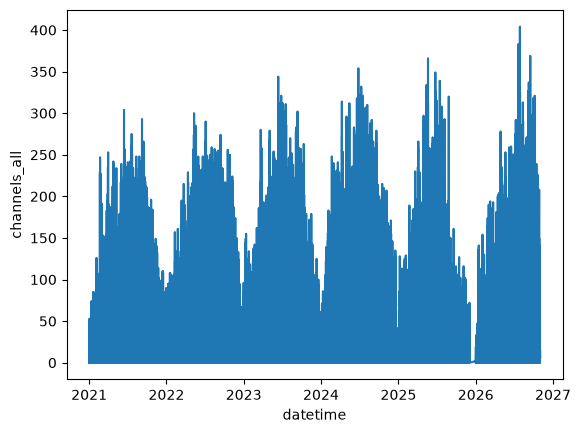

In [3]:
sns.lineplot(x=counters["datetime"], y=counters["channels_all"])

In [17]:
from sklearn.model_selection import train_test_split

features = counters.select(
        pl.col("site_temperature"),
        pl.col("site_rain_accumulation"),
        pl.col("datetime").dt.hour().alias("hour"),
        pl.col("datetime").dt.weekday().alias("weekday"),
        pl.col("datetime").dt.month().alias("month"),
        pl.col("datetime").dt.year().alias("year"),
    )
target = counters["channels_all"]/counters["channels_all"].median()

features_train, features_test, target_train, target_test = train_test_split(features, target, test_size=0.1, random_state=67)

In [18]:
def date_features(df):
    return df.select(
        pl.col("site_temperature"),
        pl.col("site_rain_accumulation"),
        pl.col("datetime").dt.hour().alias("hour"),
        pl.col("datetime").dt.weekday().alias("weekday"),
        pl.col("datetime").dt.month().alias("month"),
        pl.col("datetime").dt.year().alias("year"),
    )

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import StandardScaler

baseline = make_pipeline(
    StandardScaler(),
    PoissonRegressor()
)

X_train = features_train
baseline.fit(X_train, target_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('poissonregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['site_temperature','site_rain_accumulation','hour','weekday','month', 'year']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [20]:
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, mean_poisson_deviance, r2_score

scores = [root_mean_squared_error, mean_absolute_error, mean_poisson_deviance, r2_score]


median_prediction = target_test*0 + target_train.mean()
print([score(target_test, median_prediction) for score in scores])

[1.9535683520521252, 1.5027130236609265, 2.0250488288708635, -0.00040643282146546333]


In [21]:
baseline_pred_test = baseline.predict(features_test)
print([score(target_test, baseline_pred_test) for score in scores])

[1.741125975616281, 1.2857364464945917, 1.5781966657634399, 0.2053431286735029]


In [24]:
from sklearn.ensemble import HistGradientBoostingRegressor

gbd = HistGradientBoostingRegressor(loss="poisson")

X_train = features_train
gbd.fit(X_train, target_train)

X_test = features_test
gbd_pred_test = gbd.predict(features_test)
print([score(target_test, gbd_pred_test) for score in scores])


[0.6796785167639661, 0.4044754969918912, 0.18789754847519696, 0.87890496431148]


## Partial dependence of the HGBD model

Thin blue lines are ICE curves (one per sampled test row), the orange line is their average (the partial dependence).

In [25]:
from sklearn.inspection import PartialDependenceDisplay

# PartialDependenceDisplay can't read polars frames or integer columns, so give it a float pandas copy
X_pdp = features_test.cast(pl.Float64).to_pandas()

def plot_dependence(feature):
    fig, ax = plt.subplots(figsize=(8, 4))
    PartialDependenceDisplay.from_estimator(
        gbd, X_pdp, [feature],
        kind="both", subsample=300, random_state=0,
        ice_lines_kw={"alpha": 0.1},
        pd_line_kw={"color": "tab:orange", "lw": 3},
        ax=ax,
    )
    plt.show()

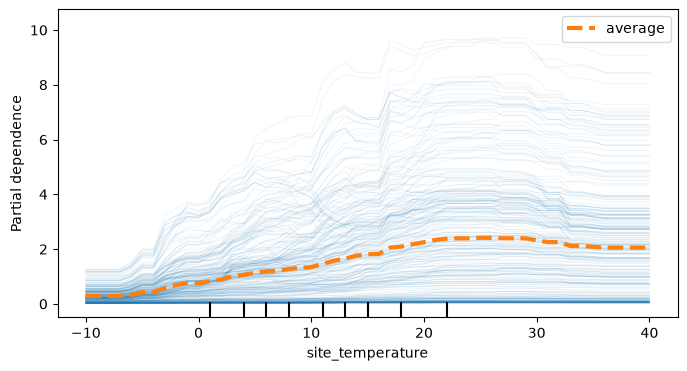

In [26]:
plot_dependence("site_temperature")

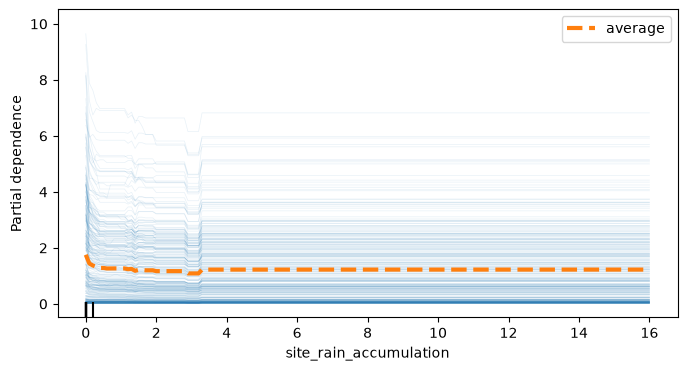

In [27]:
plot_dependence("site_rain_accumulation")

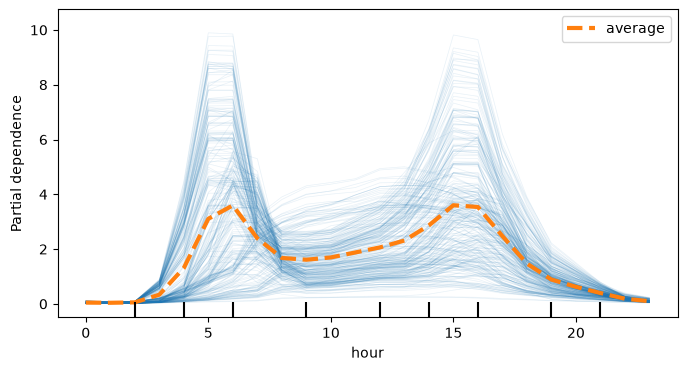

In [28]:
plot_dependence("hour")

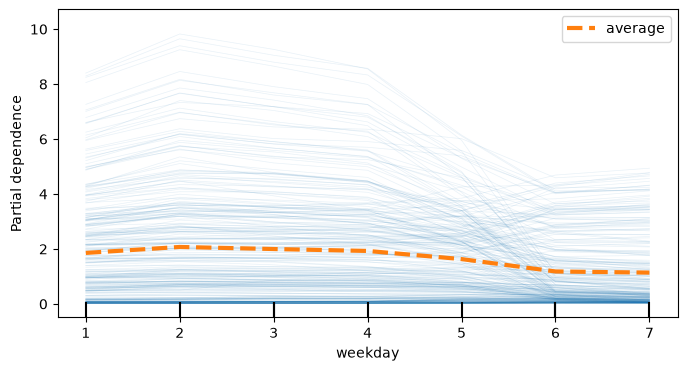

In [29]:
plot_dependence("weekday")

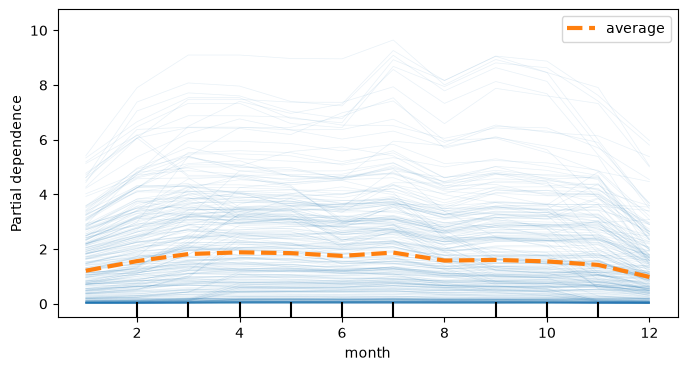

In [30]:
plot_dependence("month")

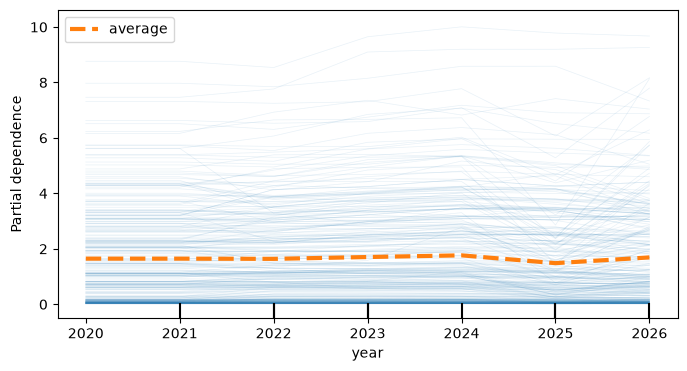

In [31]:
plot_dependence("year")

In [ ]:
counter_id = 100034894
counters = pl.read_csv("../../data/counters_hourly.csv", try_parse_dates=True).filter(pl.col("counter_site_id") == counter_id)

## Does the HGBD model transfer to the other counters?

`gbd` was trained on counter 100034894 only. For every counter, normalize `channels_all` by that counter's median (as in the training target), split it like above (90/10, `random_state=67`) and score three predictions on its test split:

- **constant**: the mean of the training split
- **transferred**: `gbd` as trained above, unchanged
- **own**: an HGBD with the same settings, trained on that counter's own training split (a ceiling for what these features can do)

In [ ]:
all_counters = (
    pl.read_csv("../../data/counters_hourly.csv", try_parse_dates=True)
    .with_columns(target=pl.col("channels_all") / pl.col("channels_all").median().over("counter_site_id"))
)

# gbd never saw missing weather, so drop those rows (100042487 has no weather at all, 100043761 partly)
print(
    all_counters.filter(pl.col("site_temperature").is_null() | pl.col("site_rain_accumulation").is_null())
    .group_by("counter_site_id").len()
)
all_counters = all_counters.drop_nulls(["site_temperature", "site_rain_accumulation"])

In [ ]:
rows = []
for (cid,), df in all_counters.group_by("counter_site_id"):
    X_tr, X_te, y_tr, y_te = train_test_split(date_features(df), df["target"], test_size=0.1, random_state=67)
    own = HistGradientBoostingRegressor(loss="poisson").fit(X_tr, y_tr)
    predictions = {
        "constant": np.full(len(y_te), y_tr.mean()),
        "transferred": gbd.predict(X_te),
        "own": own.predict(X_te),
    }
    for model, pred in predictions.items():
        rows.append({
            "counter_site_id": cid,
            "model": model,
            "median": df["channels_all"].median(),
            **{score.__name__: score(y_te, pred) for score in scores},
        })

transfer_scores = pl.DataFrame(rows)
transfer_scores.group_by("model").agg(pl.exclude("counter_site_id", "median").median())

In [ ]:
r2 = (
    transfer_scores.pivot(on="model", index=["counter_site_id", "median"], values="r2_score")
    .with_columns(gap=pl.col("own") - pl.col("transferred"))
    .sort("transferred")
)
with pl.Config(tbl_rows=-1):
    display(r2)

### Why does it fail on some counters?

Compare the average daily profile of the normalized counts (weekdays vs. weekends) between counters. `weekday_peak` is the highest hourly weekday mean, in multiples of the counter's median.

In [ ]:
profiles = (
    all_counters
    .with_columns(hour=pl.col("datetime").dt.hour(), weekend=pl.col("datetime").dt.weekday() >= 6)
    .group_by("counter_site_id", "weekend", "hour")
    .agg(pl.col("target").mean())
    .sort("hour")
)
r2 = r2.join(
    profiles.filter(~pl.col("weekend")).group_by("counter_site_id").agg(weekday_peak=pl.col("target").max()),
    on="counter_site_id",
)

others = r2.filter(pl.col("counter_site_id") != counter_id)
print(others.select(
    pl.corr("transferred", "weekday_peak", method="spearman").alias("spearman(transferred R², weekday_peak)"),
    pl.corr("transferred", "median", method="spearman").alias("spearman(transferred R², median)"),
))

In [ ]:
BLUE, TRAIN = "#257de0", "#1a1a1a"
trained_on = r2.filter(pl.col("counter_site_id") == counter_id)

fig, (ax_own, ax_peak) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, x, xlabel in [
    (ax_own, "own", "R² of a model trained on the counter itself"),
    (ax_peak, "weekday_peak", "Weekday peak (multiples of the counter's median)"),
]:
    ax.axhline(0, color="#9c9c9c", lw=1, ls="--")
    ax.scatter(others[x], others["transferred"], s=40, color=BLUE, edgecolor="white", lw=1, label="other counters")
    ax.scatter(trained_on[x], trained_on["transferred"], s=60, color=TRAIN, edgecolor="white", lw=1, label=f"{counter_id} (training counter)")
    ax.set_xlabel(xlabel)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)

ax_own.plot([0.65, 1], [0.65, 1], color="#9c9c9c", lw=1, label="transferred = own")
ax_own.set_ylabel("R² of the transferred model")
ax_own.text(0.66, 0.03, "constant prediction", color="#6b6b6b", fontsize=9)
ax_own.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 0.08))
fig.suptitle("Test R² of the transferred model per counter")
fig.tight_layout()
plt.show()

In [ ]:
best_other = others.sort("transferred")["counter_site_id"][-1]
worst = others.sort("transferred")["counter_site_id"][:2].to_list()
shown = {
    counter_id: (TRAIN, "training counter"),
    best_other: (BLUE, "best transfer"),
    worst[0]: ("#f47230", "worst transfer"),
    worst[1]: ("#00b894", "2nd worst transfer"),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, weekend in zip(axes, [False, True]):
    for cid, (color, role) in shown.items():
        p = profiles.filter((pl.col("counter_site_id") == cid) & (pl.col("weekend") == weekend))
        ax.plot(p["hour"], p["target"], color=color, lw=2, label=f"{cid} ({role})")
    ax.set_title("Weekend" if weekend else "Weekday")
    ax.set_xlabel("hour (UTC)")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mean count / counter median")
axes[1].legend(frameon=False, loc="upper right")
fig.tight_layout()
plt.show()

### Conclusion

No, not just as well. Over the other counters the transferred model reaches a median test R² of about 0.4, against about 0.84 for a model trained on each counter itself (and 0.88 on the training counter). It still beats the constant prediction on most counters, but on about a dozen it is *worse* than predicting a constant.

The timing of the daily profile is similar everywhere (rush hours at the same hours, weekend bump around midday), so that part transfers. What doesn't transfer is the **amplitude**: dividing by the median fixes the level but not how peaked the profile is. The training counter peaks at almost 5× its median; the worst counters (mostly the busy ones, median > 100/h) only reach about 2.5×, because they carry much more off-peak traffic. The transferred model predicts the training counter's peaks there and overshoots by a factor of ~2 every rush hour.